| BERT BASE |
Métricas medidas com SPAN com 10 épocas e 30 experimentos no VSCode.

In [1]:
# Importações necessárias

import pandas as pd
import csv
import re
import torch
import numpy as np
import matplotlib.pyplot as plt
from typing import List, Tuple, Dict, Optional
from datasets import Dataset, DatasetDict
from transformers import (AutoTokenizer, AutoModelForTokenClassification, TrainingArguments, Trainer, DataCollatorForTokenClassification, EarlyStoppingCallback)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from datasets import concatenate_datasets

from transformers import logging as hf_logging
hf_logging.set_verbosity_error()

import evaluate
metric = evaluate.load("seqeval")

c:\Users\Myllena\Downloads\ic_bootstrap\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Definição dos rótulos BIO
lista_rotulos = ["O", "B-WRONG", "I-WRONG"]
label_to_id = {label: i for i, label in enumerate(lista_rotulos)}
id_to_label = {i: label for i, label in enumerate(lista_rotulos)}

In [3]:
def compute_metrics(p):
    predictions, labels = p
    predictions = np.argmax(predictions, axis=2)

    # Remove os índices de ignorados (-100) e converte para labels de texto
    true_predictions = [
        [id_to_label[p] for (p, l) in zip(prediction, label) if l != -100]
        for prediction, label in zip(predictions, labels)
    ]
    true_labels = [
        [id_to_label[l] for (p, l) in zip(prediction, label) if l != -100]
        for prediction, label in zip(predictions, labels)
    ]

    results = metric.compute(predictions=true_predictions, references=true_labels)
    
    precision = results["overall_precision"]
    recall = results["overall_recall"]

    # F0.5 Score
    if precision + recall == 0: # Para evitar divisões por 0
        f0_5=0.0

    else:
        f0_5= (1+0.5**2) * (precision*recall) / ((0.5**2 * precision) + recall)

    return {
        "precision": precision,
        "recall": recall,
        "f0_5": f0_5,
        "accuracy": results["overall_accuracy"],
    }

In [4]:
import torch
device = torch.device('cuda')
print(f"Usando dispositivo: {device}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"CUDA version: {torch.version.cuda}")

Usando dispositivo: cuda
PyTorch version: 2.12.0+cu126
CUDA available: True
CUDA version: 12.6


In [5]:
# Lê arquivo CONLL (TSV)

def ler_conll(
    path: str,
    *,
    ignore_header_regex: str = r"^\s*Sentença\s+Original\s+N[°º]\s*\d+",
    allow_space_in_token: bool = False,
    strict_two_columns: bool = False,
    verbose: bool = True,
) -> Tuple[List[List[str]], List[List[str]]]:
    header_pat = re.compile(ignore_header_regex, flags=re.IGNORECASE)
    tokens_per_sent, tags_per_sent = [], []
    cur_tokens, cur_tags = [], []

    def flush_sentence():
        nonlocal cur_tokens, cur_tags
        if cur_tokens:
            tokens_per_sent.append(cur_tokens)
            tags_per_sent.append(cur_tags)
        cur_tokens, cur_tags = [], []

    with open(path, "r", encoding="utf-8") as f:
        for lineno, raw in enumerate(f, start=1):
            line = raw.rstrip("\n")

            # Ignora linhas de cabeçalho por sentença
            if header_pat.search(line):
                flush_sentence()
                continue

            # Delimitador de sentença
            if line.strip() == "":
                flush_sentence()
                continue

            # Tenta split por TAB primeiro, senão por espaço
            if "\t" in line:
                parts = line.split("\t")
            else:
                # Divide por qualquer espaço
                parts = line.strip().split()

            if strict_two_columns:
                if len(parts) != 2:
                    if verbose:
                        print(f"[AVISO] Linha {lineno} ignorada (esperado 2 colunas): {line}")
                    continue
                token, tag = parts[0], parts[1]
            else:
                if len(parts) < 2:
                    if verbose:
                        print(f"[AVISO] Linha {lineno} ignorada (colunas insuficientes): {line}")
                    continue
                if allow_space_in_token:
                    # Última coluna é tag; o resto é token (pode conter espaços/tabs)
                    *token_parts, tag = parts
                    token = " ".join(token_parts)
                else:
                    # Primeira é token, última é tag (se houver colunas no meio, descartamos/avisamos)
                    token, tag = parts[0], parts[-1]
                    if len(parts) > 2 and verbose:
                        print(f"[OBSERVAÇÃO] Linha {lineno} possuía colunas extras; usando 1ª como token e última como tag.")

            # Sanidade básica da tag
            if not tag or tag.isspace():
                if verbose:
                    print(f"[AVISO] Linha {lineno} com tag vazia; ignorada: {line}")
                continue

            cur_tokens.append(token)
            cur_tags.append(tag)

    # Última sentença (se não terminar com linha em branco)
    flush_sentence()

    return tokens_per_sent, tags_per_sent

In [6]:
# Mapeia Label2ID e ID2Label

def build_label_maps(tags_per_sent: List[List[str]]) -> Tuple[Dict[str, int], Dict[int, str]]:
    labels = set()
    for sent_tags in tags_per_sent:
        labels.update(sent_tags)

    labels = list(labels)

    if "O" in labels:
        labels.remove("O")
        labels = ["O"] + sorted(labels)
    else:
        labels = sorted(labels)

    label2id = {lab: i for i, lab in enumerate(labels)} # Converte texto em número ['O': 0, 'B-WRONG': 1, 'I-WRONG': 2]
    id2label = {i: lab for lab, i in label2id.items()} # Converte número em texto [0: 'O', 1: 'B-WRONG', 2: 'I-WRONG']
    return label2id, id2label

In [7]:
# Constrói um dataset Hugging Face com colunas de tokens (List[str]) e ner_tags (List[int]).

def make_hf_dataset_from_tokens(
    tokens_per_sent: List[List[str]],
    tags_per_sent: List[List[str]],
    label2id: Optional[Dict[str, int]] = None,
) -> Tuple[Dataset, Dict[str, int]]:

    # Verifica se as sentenças de tokens e as sentenças de tags são equivalentes (mesmo número)
    assert len(tokens_per_sent) == len(tags_per_sent), "tokens e tags desalinhados"

    # Associa Label2ID ao mapeamento das tags feito anteriormente
    if label2id is None:
        label2id, _ = build_label_maps(tags_per_sent)

    # Tags desconhecidas serão associadas à tag O
    O_ID = label2id.get("O", 0)

    # Mapeamento com tratamento de erro
    encoded_tags = []
    for tags in tags_per_sent:
        sentence_tags = []
        for tag in tags:
            sentence_tags.append(label2id.get(tag, O_ID)) # Verifica se tag está mapeada ou se uso o ID 0
        encoded_tags.append(sentence_tags)

    ds = Dataset.from_dict({"tokens": tokens_per_sent, "ner_tags": encoded_tags})
    return ds, label2id

In [8]:
# Função para equiparar lista de labels com lista de tokens

def tokenize_and_align_labels(batch, tokenizer, label_all_subtokens: bool = False):
    tokenized = tokenizer(
        batch["tokens"],
        truncation=True,
        padding=True,
        is_split_into_words=True,
    )

    all_labels = []
    for i, word_labels in enumerate(batch["ner_tags"]):
        # Mapeia o subtoken com a palavra original
        word_ids = tokenized.word_ids(batch_index=i)
        previous_word_id = None
        label_ids = []

        for word_id in word_ids:
            if word_id is None:
                # Caractere especial é ignorado
                label_ids.append(-100)
            elif word_id != previous_word_id:
                # Primeiro pedaço da palavra recebe tag original
                label_ids.append(word_labels[word_id])
            else:
                # Sub-token da mesma palavra (word) é alinhado à label original
                label_ids.append(word_labels[word_id] if label_all_subtokens else -100)
            previous_word_id = word_id

        all_labels.append(label_ids)

    tokenized["labels"] = all_labels
    return tokenized


In [9]:
# Função que retorna o objeto DatasetDict para o treinamento do modelo a partir das funções anteriores.

def load_custom_conll_dataset(
    files: Dict[str, str] | str,
    *,
    fixed_label2id: Optional[Dict[str, int]] = None,
    allow_space_in_token: bool = False,
    strict_two_columns: bool = False,
    verbose: bool = True,
) -> Tuple[DatasetDict, Dict[str, int], Dict[int, str]]:

    if isinstance(files, str):
        files = {"train": files}

    datasets_splits = {}
    cache_tokens = {}
    cache_tags = {}

    # Lê os splits
    for split_name, path in files.items():
        tokens_per_sent, tags_per_sent = ler_conll(
            path,
            allow_space_in_token=allow_space_in_token,
            strict_two_columns=strict_two_columns,
            verbose=verbose,
        )
        cache_tokens[split_name] = tokens_per_sent
        cache_tags[split_name] = tags_per_sent

    # Determinar o mapeamento de labels
    if fixed_label2id is not None:
        # Mapeamento fixo (BIO)
        accumulated_label2id = fixed_label2id
    else:
        # Remapeaia todas as tags caso não tenha labels definidas (fallback)
        all_tags = []
        for split_name in files.keys():
            all_tags.extend(cache_tags[split_name])
        accumulated_label2id, _ = build_label_maps(all_tags)

    accumulated_id2label = {i: lab for lab, i in accumulated_label2id.items()}

    # Constrói datasets usando o mapeamento (BIO)
    for split_name in files.keys():
        ds, _ = make_hf_dataset_from_tokens(
            cache_tokens[split_name],
            cache_tags[split_name],
            label2id=accumulated_label2id,
        )
        datasets_splits[split_name] = ds

    dset = DatasetDict(datasets_splits)
    return dset, accumulated_label2id, accumulated_id2label

In [10]:
# Carregamento do Dataset já com os labels BIO
path_treino = "train_bio.tsv"
path_teste = "test_bio.tsv"
path_validacao = "val_bio.tsv"

dataset, _, _ = load_custom_conll_dataset(
      files={"train": path_treino, "test": path_teste, "validation": path_validacao},
      fixed_label2id=label_to_id,
      allow_space_in_token=False,
      strict_two_columns=False,
      verbose=True,
)

# Unificação dos dados para que o sorteio 80/20 seja global a cada rodada
full_dataset = concatenate_datasets([
    dataset["train"],
    dataset["test"],
    dataset["validation"]
])

num_experimentos = 30
resultados_experimentos = [] # Lista para armazenar métricas de cada rodada

print(full_dataset)
print("labels:", label_to_id)

Dataset({
    features: ['tokens', 'ner_tags'],
    num_rows: 19250
})
labels: {'O': 0, 'B-WRONG': 1, 'I-WRONG': 2}


In [11]:
tokenizer = AutoTokenizer.from_pretrained("neuralmind/bert-base-portuguese-cased")

# Tokenização + alinhamento das labels
tokenized_dataset = dataset.map(
    lambda batch: tokenize_and_align_labels(batch, tokenizer, label_all_subtokens=False), # Aplica a função para alinhamento de tokens e tags
    batched=True # Processa várias sentenças simultaneamente
)

# Carregamento do Modelo
model = AutoModelForTokenClassification.from_pretrained(
    "neuralmind/bert-base-portuguese-cased",
    num_labels=len(lista_rotulos),
    id2label=id_to_label,
    label2id=label_to_id,
    use_safetensors=True
)

model.to(device)

print(f"\nModelo movido para: {device}")
print(f"\nOs rótulos foram definidos como: \n{model.config.id2label}")

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 4846.89it/s]



Modelo movido para: cuda

Os rótulos foram definidos como: 
{0: 'O', 1: 'B-WRONG', 2: 'I-WRONG'}


In [12]:
# Cria o data collator que faz padding dinâmico
data_collator = DataCollatorForTokenClassification(
    tokenizer=tokenizer,
    padding=True,
)

*** INÍCIO DO CICLO DE 30 EXPERIMENTOS COM BERT BASE ***


Loading weights: 100%|██████████| 197/197 [00:00<?, ?it/s]


{'loss': '0.9236', 'grad_norm': '5.988', 'learning_rate': '1.8e-05', 'epoch': '1'}
{'eval_loss': '0.2005', 'eval_precision': '0.7077', 'eval_recall': '0.5751', 'eval_f0_5': '0.6765', 'eval_accuracy': '0.9456', 'eval_runtime': '103.1', 'eval_samples_per_second': '37.33', 'eval_steps_per_second': '4.673', 'epoch': '1'}
{'loss': '0.6599', 'grad_norm': '1.676', 'learning_rate': '1.6e-05', 'epoch': '2'}
{'eval_loss': '0.2038', 'eval_precision': '0.7212', 'eval_recall': '0.6003', 'eval_f0_5': '0.6932', 'eval_accuracy': '0.9451', 'eval_runtime': '103.6', 'eval_samples_per_second': '37.14', 'eval_steps_per_second': '4.65', 'epoch': '2'}
{'loss': '0.493', 'grad_norm': '4.089', 'learning_rate': '1.4e-05', 'epoch': '3'}
{'eval_loss': '0.2209', 'eval_precision': '0.7126', 'eval_recall': '0.6054', 'eval_f0_5': '0.6882', 'eval_accuracy': '0.9461', 'eval_runtime': '103.6', 'eval_samples_per_second': '37.16', 'eval_steps_per_second': '4.653', 'epoch': '3'}
{'loss': '0.3592', 'grad_norm': '9.161', 'lea

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 14040.17it/s]


{'loss': '0.9195', 'grad_norm': '7.685', 'learning_rate': '1.8e-05', 'epoch': '1'}
{'eval_loss': '0.2047', 'eval_precision': '0.6975', 'eval_recall': '0.5938', 'eval_f0_5': '0.674', 'eval_accuracy': '0.9454', 'eval_runtime': '97.97', 'eval_samples_per_second': '39.3', 'eval_steps_per_second': '4.92', 'epoch': '1'}
{'loss': '0.6683', 'grad_norm': '3.711', 'learning_rate': '1.6e-05', 'epoch': '2'}
{'eval_loss': '0.2272', 'eval_precision': '0.7459', 'eval_recall': '0.5904', 'eval_f0_5': '0.7086', 'eval_accuracy': '0.9479', 'eval_runtime': '95.21', 'eval_samples_per_second': '40.44', 'eval_steps_per_second': '5.062', 'epoch': '2'}
{'loss': '0.4934', 'grad_norm': '6.082', 'learning_rate': '1.4e-05', 'epoch': '3'}
{'eval_loss': '0.226', 'eval_precision': '0.6577', 'eval_recall': '0.6208', 'eval_f0_5': '0.65', 'eval_accuracy': '0.9437', 'eval_runtime': '98.13', 'eval_samples_per_second': '39.23', 'eval_steps_per_second': '4.912', 'epoch': '3'}
{'loss': '0.3688', 'grad_norm': '18.75', 'learnin

...

{'loss': '0.9239', 'grad_norm': '1.545', 'learning_rate': '1.8e-05', 'epoch': '1'}
{'eval_loss': '0.1913', 'eval_precision': '0.7383', 'eval_recall': '0.5996', 'eval_f0_5': '0.7056', 'eval_accuracy': '0.947', 'eval_runtime': '93.27', 'eval_samples_per_second': '41.28', 'eval_steps_per_second': '5.168', 'epoch': '1'}
{'loss': '0.6665', 'grad_norm': '2.989', 'learning_rate': '1.6e-05', 'epoch': '2'}
{'eval_loss': '0.1939', 'eval_precision': '0.6981', 'eval_recall': '0.6402', 'eval_f0_5': '0.6857', 'eval_accuracy': '0.9487', 'eval_runtime': '96.57', 'eval_samples_per_second': '39.87', 'eval_steps_per_second': '4.991', 'epoch': '2'}
{'loss': '0.5023', 'grad_norm': '2.982', 'learning_rate': '1.4e-05', 'epoch': '3'}
{'eval_loss': '0.2028', 'eval_precision': '0.6905', 'eval_recall': '0.6428', 'eval_f0_5': '0.6804', 'eval_accuracy': '0.9457', 'eval_runtime': '96.6', 'eval_samples_per_second': '39.85', 'eval_steps_per_second': '4.989', 'epoch': '3'}
{'loss': '0.3656', 'grad_norm': '10.29', 'lea

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 12067.03it/s]


{'loss': '0.901', 'grad_norm': '5.31', 'learning_rate': '1.8e-05', 'epoch': '1'}
{'eval_loss': '0.2136', 'eval_precision': '0.7005', 'eval_recall': '0.5776', 'eval_f0_5': '0.6719', 'eval_accuracy': '0.9441', 'eval_runtime': '99.85', 'eval_samples_per_second': '38.56', 'eval_steps_per_second': '4.827', 'epoch': '1'}
{'loss': '0.6566', 'grad_norm': '1.083', 'learning_rate': '1.6e-05', 'epoch': '2'}
{'eval_loss': '0.2258', 'eval_precision': '0.7136', 'eval_recall': '0.5914', 'eval_f0_5': '0.6853', 'eval_accuracy': '0.9458', 'eval_runtime': '96.9', 'eval_samples_per_second': '39.73', 'eval_steps_per_second': '4.974', 'epoch': '2'}
{'loss': '0.4963', 'grad_norm': '4.495', 'learning_rate': '1.4e-05', 'epoch': '3'}
{'eval_loss': '0.2329', 'eval_precision': '0.6614', 'eval_recall': '0.6293', 'eval_f0_5': '0.6547', 'eval_accuracy': '0.9415', 'eval_runtime': '99.68', 'eval_samples_per_second': '38.62', 'eval_steps_per_second': '4.835', 'epoch': '3'}
{'loss': '0.3643', 'grad_norm': '19.23', 'lear

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 25937.90it/s]


{'loss': '0.917', 'grad_norm': '2.34', 'learning_rate': '1.8e-05', 'epoch': '1'}
{'eval_loss': '0.1973', 'eval_precision': '0.7148', 'eval_recall': '0.6121', 'eval_f0_5': '0.6916', 'eval_accuracy': '0.9445', 'eval_runtime': '98.05', 'eval_samples_per_second': '39.27', 'eval_steps_per_second': '4.916', 'epoch': '1'}
{'loss': '0.6635', 'grad_norm': '12.85', 'learning_rate': '1.6e-05', 'epoch': '2'}
{'eval_loss': '0.2078', 'eval_precision': '0.7104', 'eval_recall': '0.636', 'eval_f0_5': '0.6942', 'eval_accuracy': '0.9426', 'eval_runtime': '97.9', 'eval_samples_per_second': '39.33', 'eval_steps_per_second': '4.923', 'epoch': '2'}
{'loss': '0.503', 'grad_norm': '1.066', 'learning_rate': '1.4e-05', 'epoch': '3'}
{'eval_loss': '0.2154', 'eval_precision': '0.7032', 'eval_recall': '0.6398', 'eval_f0_5': '0.6895', 'eval_accuracy': '0.9447', 'eval_runtime': '94.87', 'eval_samples_per_second': '40.58', 'eval_steps_per_second': '5.081', 'epoch': '3'}
{'loss': '0.3625', 'grad_norm': '4.624', 'learni

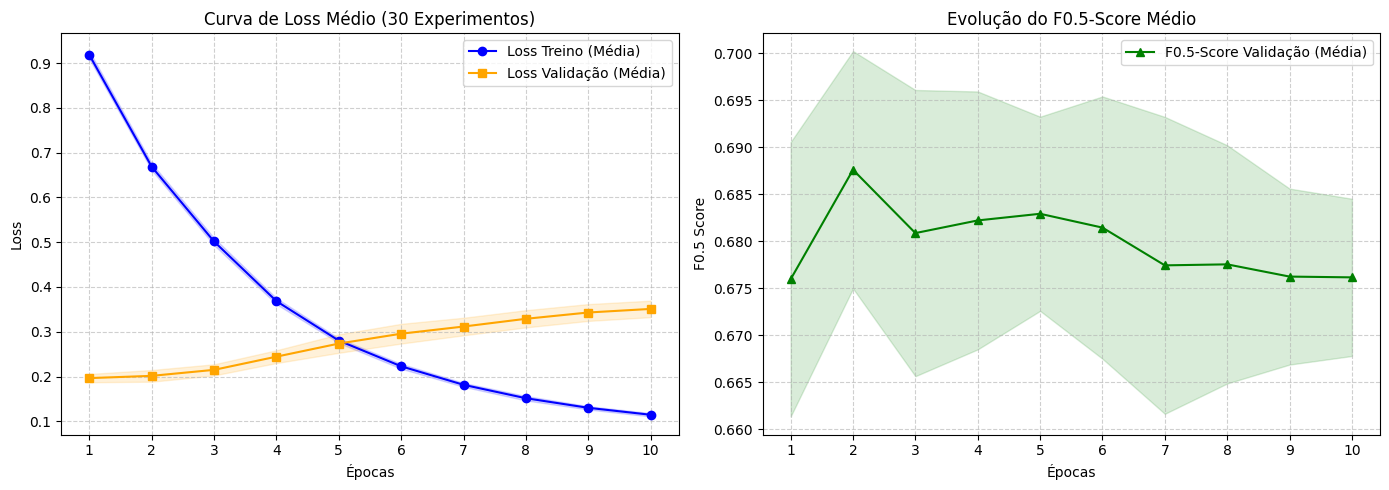

In [13]:
import gc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForTokenClassification, Trainer, TrainingArguments

nome_modelo = "neuralmind/bert-base-portuguese-cased"

# Argumentos de Treinamento
num_experimentos = 30
resultados_experimentos = []

# Listas para armazenar o histórico de loss e métricas por época de TODOS os experimentos
todos_historicos = []

print(f"*** INÍCIO DO CICLO DE {num_experimentos} EXPERIMENTOS COM BERT BASE ***")

for i in range(num_experimentos):
    current_seed = 100 + i

    # Requisito 1: Shuffle Dinâmico em memória
    ds_split = full_dataset.shuffle(seed=current_seed).train_test_split(
        test_size=0.2, seed=current_seed
    )

    # Tokenização do split atual
    tokenized_ds = ds_split.map(
        lambda batch: tokenize_and_align_labels(
            batch, tokenizer, label_all_subtokens=False
        ),
        batched=True,
        load_from_cache_file=False,
    )

    # Requisito: Reinicialização do Modelo (Essencial para independência estatística)
    model = AutoModelForTokenClassification.from_pretrained(
        nome_modelo,
        num_labels=len(lista_rotulos),
        id2label=id_to_label,
        label2id=label_to_id,
    ).to(device)

    output_dir_atual = f"./temp_results/exp_{i+1}"

    training_args = TrainingArguments(
        output_dir=output_dir_atual,
        eval_strategy="epoch",  # Avalia a cada época para registrar eval_loss e métricas
        logging_strategy="epoch",  # Registra logs do treino a cada época
        save_strategy="no",  # Evita salvar checkpoints pesados no disco
        learning_rate=2e-5,
        per_device_train_batch_size=4,  # Batch size reduzido para evitar Out Of Memory Error
        gradient_accumulation_steps=4,  # Acumula gradientes para simular batch size de 16
        num_train_epochs=10,
        weight_decay=0.01,
        disable_tqdm=True,
        report_to=[],
        fp16=torch.cuda.is_available(),
    )

    # Requisito 2: Trainer configurado dentro do loop
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_ds["train"],
        eval_dataset=tokenized_ds["test"],
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )

    # Execução do treino da rodada i
    trainer.train()

    # Coleta de histórico de perdas e métricas por época
    log_history = trainer.state.log_history
    train_loss_ep = []
    eval_loss_ep = []
    f05_ep = []

    for log in log_history:
        if "loss" in log:
            train_loss_ep.append(log["loss"])
        if "eval_loss" in log:
            eval_loss_ep.append(log["eval_loss"])
            f05_ep.append(log.get("eval_f0_5", 0.0))

    todos_historicos.append(
        {
            "train_loss": train_loss_ep,
            "eval_loss": eval_loss_ep,
            "eval_f0_5": f05_ep,
        }
    )

    # Requisito 3: Coleta de métricas essenciais no teste
    metrics = trainer.evaluate(eval_dataset=tokenized_ds["test"])
    resultados_experimentos.append(
        {
            "Precision": metrics["eval_precision"],
            "Recall": metrics["eval_recall"],
            "F0.5-Score": metrics["eval_f0_5"],
            "Accuracy": metrics["eval_accuracy"],
        }
    )

    print(
        f"✅ Rodada {i+1}/30 finalizada (Seed: {current_seed}) | F0_5: {metrics['eval_f0_5']:.4f}"
    )

    # Limpeza de memória após cada experimento
    del model
    del trainer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# --- Requisito 4: Agregação Estatística Final e Salvamento em Arquivos ---
df_resultados = pd.DataFrame(resultados_experimentos)

# Salvamento das métricas individuais por rodada em CSV
df_resultados.to_csv("resultados_bertbase.csv", index=False)
print(
    "\n Os resultados dos 30 experimentos foram salvos em 'resultados_bertbase.csv'"
)

stats_media = df_resultados.mean()
stats_desvio = df_resultados.std()

# Montagem do texto do relatório estatístico
linhas_relatorio = []
linhas_relatorio.append("=" * 45)
linhas_relatorio.append(
    "📊 RELATÓRIO ESTATÍSTICO DE SPANS (30 EXPERIMENTOS, 10 ÉPOCAS)"
)
linhas_relatorio.append("=" * 45)
for metrica in df_resultados.columns:
    linhas_relatorio.append(
        f"{metrica:10}: {stats_media[metrica]:.4f} (± {stats_desvio[metrica]:.4f})"
    )
linhas_relatorio.append("=" * 45)

texto_relatorio = "\n".join(linhas_relatorio)

# Impressão na tela
print("\n" + texto_relatorio)

# SALVAMENTO DO RELATÓRIO ESTATÍSTICO EM ARQUIVO .TXT
with open("relatorio_estatistico.txt", "w", encoding="utf-8") as f:
    f.write(texto_relatorio)

print(
    "\n📄 Relatório estatístico salvo com sucesso em 'relatorio_estatistico.txt'!"
)

# GERAÇÃO DOS GRÁFICOS DE APRENDIZADO (MÉDIA DAS 30 RODADAS)
arr_train_loss = np.array([h["train_loss"] for h in todos_historicos])
arr_eval_loss = np.array([h["eval_loss"] for h in todos_historicos])
arr_eval_f05 = np.array([h["eval_f0_5"] for h in todos_historicos])

epocas = np.arange(1, 11)

plt.figure(figsize=(14, 5))

# 1. Gráfico de Loss (Treino vs Validação)
plt.subplot(1, 2, 1)
plt.plot(
    epocas,
    arr_train_loss.mean(axis=0),
    label="Loss Treino (Média)",
    color="blue",
    marker="o",
)
plt.plot(
    epocas,
    arr_eval_loss.mean(axis=0),
    label="Loss Validação (Média)",
    color="orange",
    marker="s",
)
plt.fill_between(
    epocas,
    arr_train_loss.mean(axis=0) - arr_train_loss.std(axis=0),
    arr_train_loss.mean(axis=0) + arr_train_loss.std(axis=0),
    color="blue",
    alpha=0.15,
)
plt.fill_between(
    epocas,
    arr_eval_loss.mean(axis=0) - arr_eval_loss.std(axis=0),
    arr_eval_loss.mean(axis=0) + arr_eval_loss.std(axis=0),
    color="orange",
    alpha=0.15,
)
plt.title("Curva de Loss Médio (30 Experimentos)")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.xticks(epocas)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

# 2. Gráfico de F0.5-Score
plt.subplot(1, 2, 2)
plt.plot(
    epocas,
    arr_eval_f05.mean(axis=0),
    label="F0.5-Score Validação (Média)",
    color="green",
    marker="^",
)
plt.fill_between(
    epocas,
    arr_eval_f05.mean(axis=0) - arr_eval_f05.std(axis=0),
    arr_eval_f05.mean(axis=0) + arr_eval_f05.std(axis=0),
    color="green",
    alpha=0.15,
)
plt.title("Evolução do F0.5-Score Médio")
plt.xlabel("Épocas")
plt.ylabel("F0.5 Score")
plt.xticks(epocas)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig("curva_aprendizado_loss.png", dpi=300)
plt.show()